# Étape 4 :Modélisation et comparaison : SVM, Random Forest et XGBoost

L'objectif de ce notebook est d'entraîner et de comparer trois algorithmes de Machine Learning sur la tâche de classification du statut tabagique. 

Pour garantir une évaluation robuste et éviter la fuite de données (*data leakage*), la transformation du texte en vecteurs numériques (TF-IDF) sera systématiquement intégrée dans un pipeline. De plus, une validation croisée stratifiée sera utilisée pour confirmer la stabilité des modèles avant l'évaluation finale sur le jeu de test.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, f1_score

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import optuna

## 4.1 Préparation des données

Nous isolons le texte et les annotations. 

XGBoost nécessitant des labels numériques (0, 1, 2, 3...), nous appliquons un `LabelEncoder`. 

La séparation train/test est fixée à 80/20 avec une stratification pour conserver la proportion des statuts tabagiques dans les deux ensembles.

In [2]:
df = pd.read_csv("./data/annotated_corrected.csv", sep=",")
X = df['text']

In [3]:
df.columns

Index(['id', 'text', 'label'], dtype='str')

In [ ]:
df = df[['id', 'text', 'label']]

# Encodage de la cible en entiers (requis par XGBoost)
le = LabelEncoder()
y = le.fit_transform(df['label'])
classes_names = le.classes_

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Classes : {le.classes_}")
print(f"Taille du jeu d'entraînement : {X_train.shape[0]} documents")
print(f"Taille du jeu de test : {X_test.shape[0]} documents")

Classes : ['Ancien fumeur' 'Fumeur actuel' 'Non mentionné' 'Non-fumeur']
Taille du jeu d'entraînement : 478 documents
Taille du jeu de test : 120 documents


## 4.2 Stratégie d'évaluation et automatisation

Pour comparer les modèles équitablement tout en gardant un code lisible, nous définissons une fonction de routine. 
Cette fonction va :
1. Construire le pipeline (TF-IDF + Modèle).
2. Calculer un score de validation croisée (F1-macro) sur le jeu d'entraînement pour vérifier la stabilité.
3. Entraîner le modèle sur l'intégralité du jeu d'entraînement.
4. Prédire sur le jeu de test et afficher le rapport de classification et la matrice de confusion.

In [5]:
def evaluate_model(model, name, X_train, y_train, X_test, y_test, target_names):
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
        ('clf', model)
    ])
    
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    
    print(f"{name} :")
    print(f"F1-score moyen CV (Train) : {cv_scores.mean():.3f} (+/- {cv_scores.std()*2:.3f})\n")
    
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    
    print(f"\nRapport sur le jeu de Test :")
    print(classification_report(y_test, y_pred, target_names=target_names, zero_division=0))
    
    cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(target_names)))
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
    plt.title(f'Matrice de confusion - {name}')
    plt.ylabel('Vérité terrain')
    plt.xlabel('Prédiction')
    plt.show()
    
    return {
        'Modèle': name, 
        'Accuracy': round(acc, 3), 
        'Precision (macro)': round(prec, 3), 
        'Recall (macro)': round(rec, 3), 
        'F1-score (macro)': round(f1, 3)
    }

# Liste pour stocker les résultats de chaque modèle
all_results = []

## 4.3 Entraînement des modèles 

### Support Vector Machine (SVM)

SVM Linéaire :
F1-score moyen CV (Train) : 0.541 (+/- 0.071)


Rapport sur le jeu de Test :
               precision    recall  f1-score   support

Ancien fumeur       0.64      0.88      0.74        16
Fumeur actuel       0.47      0.44      0.46        18
Non mentionné       0.94      0.79      0.86        61
   Non-fumeur       0.50      0.60      0.55        25

     accuracy                           0.71       120
    macro avg       0.64      0.68      0.65       120
 weighted avg       0.74      0.71      0.72       120



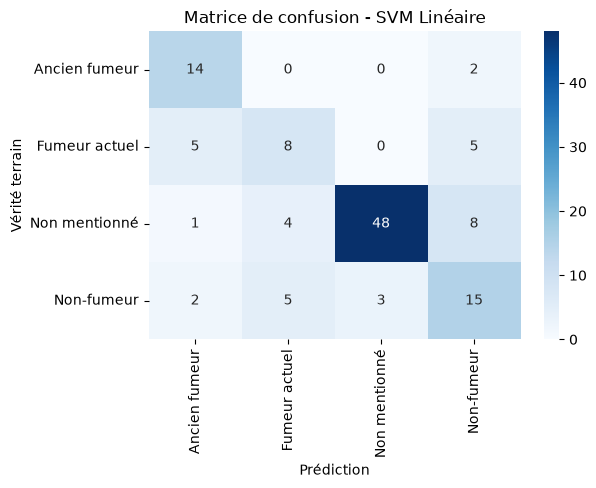

In [6]:
svm_model = SVC(kernel='linear', class_weight='balanced', random_state=42)
res_svm = evaluate_model(svm_model, "SVM Linéaire", X_train, y_train, X_test, y_test, classes_names)
all_results.append(res_svm)

### Random Forest

Random Forest :
F1-score moyen CV (Train) : 0.678 (+/- 0.152)


Rapport sur le jeu de Test :
               precision    recall  f1-score   support

Ancien fumeur       0.71      0.75      0.73        16
Fumeur actuel       0.65      0.61      0.63        18
Non mentionné       0.93      0.85      0.89        61
   Non-fumeur       0.63      0.76      0.69        25

     accuracy                           0.78       120
    macro avg       0.73      0.74      0.73       120
 weighted avg       0.80      0.78      0.79       120



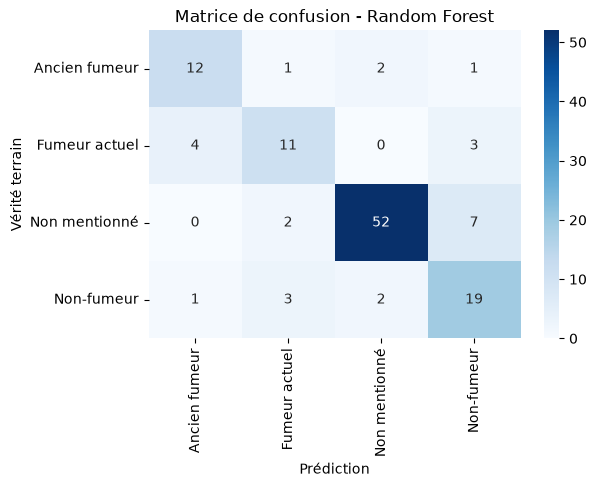

In [7]:
rf_model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
res_rf = evaluate_model(rf_model, "Random Forest", X_train, y_train, X_test, y_test, classes_names)
all_results.append(res_rf)

### XGBoost

XGBoost (Base) :
F1-score moyen CV (Train) : 0.795 (+/- 0.090)


Rapport sur le jeu de Test :
               precision    recall  f1-score   support

Ancien fumeur       0.74      0.88      0.80        16
Fumeur actuel       0.80      0.67      0.73        18
Non mentionné       0.92      0.93      0.93        61
   Non-fumeur       0.83      0.80      0.82        25

     accuracy                           0.86       120
    macro avg       0.82      0.82      0.82       120
 weighted avg       0.86      0.86      0.86       120



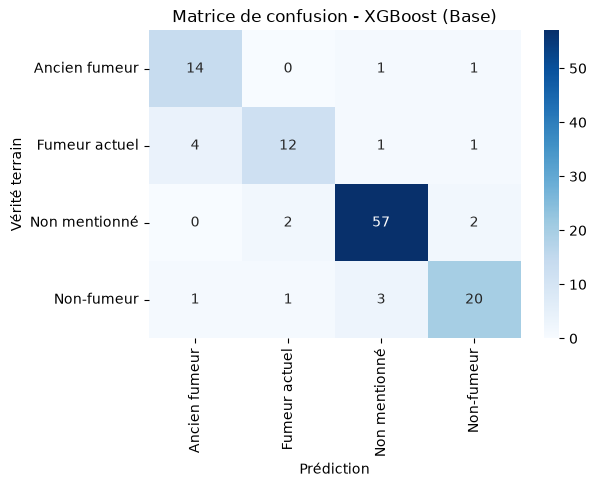

In [8]:
xgb_model = XGBClassifier(eval_metric='mlogloss', random_state=42, n_jobs=-1)
res_xgb = evaluate_model(xgb_model, "XGBoost (Base)", X_train, y_train, X_test, y_test, classes_names)
all_results.append(res_xgb)

## 4.4 Optimisation Bayésienne des Hyperparamètres (Optuna)

Pour maximiser les performances, nous allons optimiser les hyperparamètres de **XGBoost** (modèle avec les meilleures performances).
La recherche s'effectue strictement sur le jeu d'entraînement via `StratifiedKFold` pour éviter tout data leakage.

In [ ]:
# Réduction des logs Optuna pour la lisibilité du notebook
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective_hpo(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'objective': 'multi:softprob',
        'eval_metric': 'mlogloss',
        'random_state': 42,
        'n_jobs': -1
    }
    
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
        ('clf', XGBClassifier(**params))
    ])
    
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)
    
    return scores.mean()

study_hpo = optuna.create_study(direction='maximize')
study_hpo.optimize(objective_hpo, n_trials=20)

print("\nMeilleurs hyperparamètres trouvés :")
for key, value in study_hpo.best_params.items():
    print(f"  - {key}: {value}")
print(f"Meilleur F1-score macro CV estimé : {study_hpo.best_value:.4f}")


Meilleurs hyperparamètres trouvés :
  - n_estimators: 199
  - max_depth: 5
  - learning_rate: 0.10194114744937541
  - subsample: 0.998676157376475
  - colsample_bytree: 0.654445413369168
Meilleur F1-score macro CV estimé : 0.8142


## 4.5 Optimisation des Seuils de Décision

Dans les problèmes multi-classes déséquilibrés, le critère standard `argmax(probabilités)` n'est pas toujours optimal. 
Nous allons multiplier les probabilités prédites par un **vecteur de poids** (équivalent à ajuster les seuils). 

**Prévention du Data Leakage :** 
Pour ne pas optimiser ces poids sur les données qui ont servi à entraîner le modèle, nous générons des prédictions **Out-Of-Fold (OOF)** sur `X_train` grâce à `cross_val_predict`.

In [ ]:
best_xgb_params = study_hpo.best_params
best_xgb_params.update({'objective': 'multi:softprob', 'eval_metric': 'mlogloss', 'random_state': 42, 'n_jobs': -1})

best_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ('clf', XGBClassifier(**best_xgb_params))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probas = cross_val_predict(best_pipeline, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)

def objective_threshold(trial):
    # Un poids par classe
    weights = [trial.suggest_float(f'w_{i}', 0.01, 2.0) for i in range(len(classes_names))]
    
    weighted_probas = oof_probas * weights
    y_pred_oof = np.argmax(weighted_probas, axis=1)
    
    return f1_score(y_train, y_pred_oof, average='macro')

study_thresh = optuna.create_study(direction='maximize')
study_thresh.optimize(objective_threshold, n_trials=50)

# Extraction des meilleurs poids
best_weights = [study_thresh.best_params[f'w_{i}'] for i in range(len(classes_names))]

print("\nMeilleurs poids (ajustement des seuils) par classe :")
for cls_name, w in zip(classes_names, best_weights):
    print(f"  - {cls_name}: {w:.4f}")

print(f"F1-score macro CV avec seuils optimisés : {study_thresh.best_value:.4f}")


Meilleurs poids (ajustement des seuils) par classe :
  - Ancien fumeur: 0.6894
  - Fumeur actuel: 0.7206
  - Non mentionné: 0.7356
  - Non-fumeur: 0.6675
F1-score macro CV avec seuils optimisés : 0.8157


## 4.6 Évaluation finale sur le Jeu de Test

Nous entraînons maintenant le pipeline complet sur 100% de `X_train` et nous comparons :
1. Le modèle XGBoost avec HPO (sans ajustement de seuil).
2. Le modèle XGBoost avec HPO **ET** Seuils ajustés.

XGBoost (Opt. HPO + Seuils)
Rapport de Classification (Test Set)
               precision    recall  f1-score   support

Ancien fumeur       0.82      0.88      0.85        16
Fumeur actuel       0.82      0.78      0.80        18
Non mentionné       0.94      0.97      0.95        61
   Non-fumeur       0.91      0.84      0.88        25

     accuracy                           0.90       120
    macro avg       0.87      0.86      0.87       120
 weighted avg       0.90      0.90      0.90       120



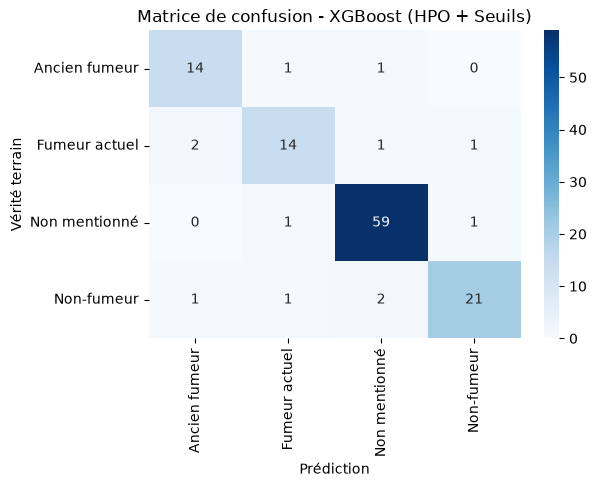

In [13]:
best_pipeline.fit(X_train, y_train)

# XGBoost
y_pred_hpo = best_pipeline.predict(X_test)
acc_hpo = accuracy_score(y_test, y_pred_hpo)
prec_hpo, rec_hpo, f1_hpo, _ = precision_recall_fscore_support(y_test, y_pred_hpo, average='macro', zero_division=0)

all_results.append({
    'Modèle': 'XGBoost (Opt. HPO)', 
    'Accuracy': round(acc_hpo, 3), 
    'Precision (macro)': round(prec_hpo, 3), 
    'Recall (macro)': round(rec_hpo, 3), 
    'F1-score (macro)': round(f1_hpo, 3)
})


# XGBoost (Opt. HPO + Seuils)
test_probas = best_pipeline.predict_proba(X_test)
# Application des poids optimisés
weighted_test_probas = test_probas * best_weights
y_pred_thresh = np.argmax(weighted_test_probas, axis=1)

acc_th = accuracy_score(y_test, y_pred_thresh)
prec_th, rec_th, f1_th, _ = precision_recall_fscore_support(y_test, y_pred_thresh, average='macro', zero_division=0)

all_results.append({
    'Modèle': 'XGBoost (Opt. HPO + Seuils)', 
    'Accuracy': round(acc_th, 3), 
    'Precision (macro)': round(prec_th, 3), 
    'Recall (macro)': round(rec_th, 3), 
    'F1-score (macro)': round(f1_th, 3)
})

print("XGBoost (Opt. HPO + Seuils)")
print("Rapport de Classification (Test Set)")
print(classification_report(y_test, y_pred_thresh, labels=np.arange(len(classes_names)), target_names=classes_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred_thresh, labels=np.arange(len(classes_names)))
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes_names, yticklabels=classes_names)
plt.title('Matrice de confusion - XGBoost (HPO + Seuils)')
plt.ylabel('Vérité terrain')
plt.xlabel('Prédiction')
plt.show()

## 4.7 Comparaison et Synthèse Générale

Ce tableau et ce graphique récapitulent la progression des modèles. 

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Modèle,,,,
SVM Linéaire,0.708,0.637,0.677,0.649
Random Forest,0.783,0.729,0.743,0.734
XGBoost (Base),0.858,0.822,0.819,0.818
XGBoost (Opt. HPO),0.900,0.874,0.865,0.869
XGBoost (Opt. HPO + Seuils),0.900,0.874,0.865,0.869


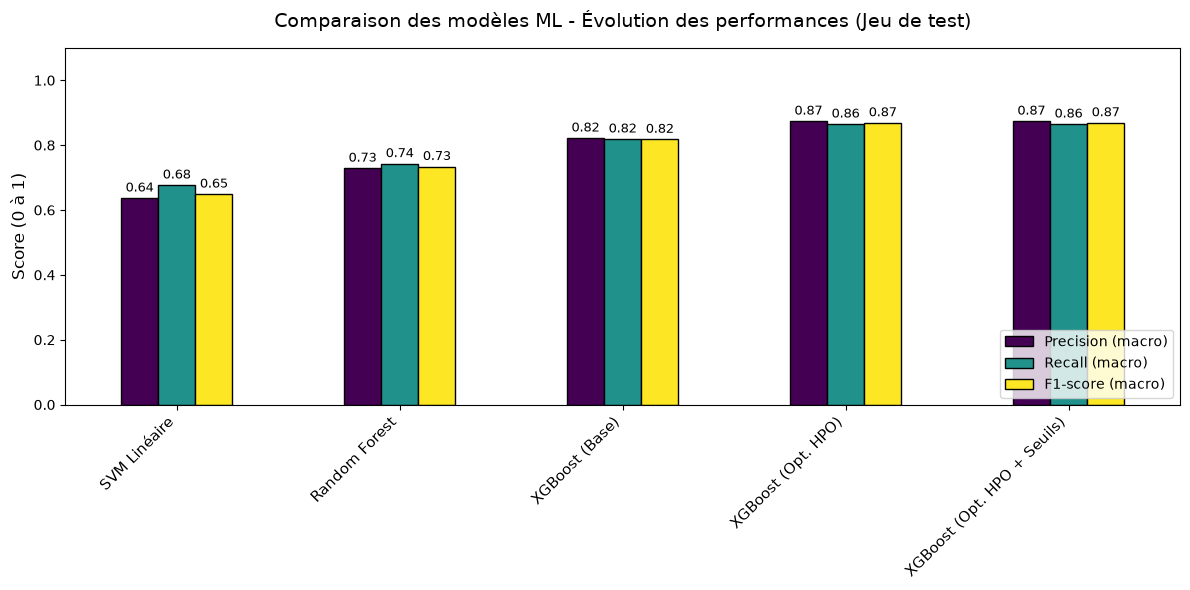

In [12]:
df_results = pd.DataFrame(all_results).set_index('Modèle')
display(df_results)

ax = df_results[['Precision (macro)', 'Recall (macro)', 'F1-score (macro)']].plot(
    kind='bar', 
    figsize=(12, 6), 
    colormap='viridis',
    edgecolor='black'
)

plt.title('Comparaison des modèles ML - Évolution des performances (Jeu de test)', fontsize=14, pad=15)
plt.ylabel('Score (0 à 1)', fontsize=12)
plt.xlabel('')
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.legend(loc='lower right')
plt.ylim(0, 1.1)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.2f}", (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center', xytext=(0, 7), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()